# Guia de investigação das APIs — **Trilha B (preenchido)**
## Qualidade do ar inadequada para corrida e ciclismo ao ar livre em São Paulo

**Disciplina:** Ciência de Dados e Aprendizado de Máquina — Prof.ª Andrea Ono Sakai
**Grupo:** Grupo 1 (Equipe 2) — Trilha B
**Integrantes:** Adrielle Stollemberger (RGM 33948844) · Victor Almeida de Aquino (RGM 32901321) · Nicolas Santos Silva (RGM ⚠️ conferir — 3287380 tem 7 dígitos) · Samir Abdul Khalek (RGM 32657994) · João Pedro Garcia Almeida (RGM 32847629)
**Repositório:** https://github.com/Adri22K/Projeto-TrilhaB

Este notebook é o `Guia_Alunos_APIs_Trilhas_B_C.ipynb` **preenchido para a Trilha B**, respondendo aos pontos da correção da Sprint 1. A Parte 3 (Trilha C) não se aplica ao grupo e foi mantida apenas como marcador.

**Como executar (Google Colab):** `Ambiente de execução → Executar tudo`. Não é preciso instalar nada (o Colab já tem `requests`, `pandas` e `matplotlib`). O notebook baixa os dados das APIs, salva o JSON **bruto** em `dados_brutos/` antes de qualquer transformação e só depois monta os DataFrames. **Salve o notebook com as saídas** (Arquivo → Salvar uma cópia no GitHub/Drive) para que a professora veja os resultados.

| Correção da Sprint 1 | Onde foi resolvido neste notebook |
|---|---|
| Evento genérico; sem classe positiva, horizonte e custo do FN | Seção 1 |
| APIs sem documentação, unidades e justificativa | Seções 2 e 7 |
| Parâmetros *hard-coded* | Seção 4 (`config` único) |
| Sem `timeout`, `raise_for_status`, `try/except` | Seção 5 (`requisitar`) |
| Resposta não inspecionada; sem JSON bruto | Seções 6, 8 e 10 |
| Só uma fonte; sem `merge` | Seções 10 e 11 (`how` e `validate` justificados) |
| Coleta misturada com transformação (média diária) | Resolução **horária** mantida; nenhuma agregação na coleta |
| Qualidade dos dados ausente | Seções 19 a 21 |
| Alvo e features ausentes | Seções 22 e 23 (com teste automático de vazamento) |

# Parte 1 — Preparação

## 1. Definição do problema

**Evento previsto:** em São Paulo, se **daqui a 24 horas** a qualidade do ar estará na classe **CETESB N3 — RUIM ou pior** em pelo menos um poluente. Em linguagem de produto: *"amanhã, neste mesmo horário, o ar vai estar bom para correr/pedalar?"*

**Classe positiva:** `qualidade_inadequada_24h = 1` quando, no instante `t + 24 h`, pelo menos uma das condições abaixo é verdadeira (limites de entrada da faixa N3 do índice CETESB, cada um na sua média de referência):

| Poluente | Média usada pela CETESB | Limite N3 (classe 1 se maior que) |
|---|---|---|
| MP10 (`pm10`) | 24 h | 100 µg/m³ |
| MP2,5 (`pm2_5`) | 24 h | 50 µg/m³ |
| O₃ (`ozone`) | 8 h | 130 µg/m³ |
| NO₂ (`nitrogen_dioxide`) | 1 h | 240 µg/m³ |
| SO₂ (`sulphur_dioxide`) | 24 h | 40 µg/m³ |
| CO (`carbon_monoxide`) | 8 h | 11 ppm |

A classe negativa (`0`) é "ar Bom ou Moderado". Escolhemos N3 porque é a faixa em que a CETESB passa a considerar efeitos para **toda** a população, e não só para grupos sensíveis — o que importa para quem faz esforço intenso.

**Horizonte:** 24 horas à frente (o atleta decide hoje o treino de amanhã no mesmo horário). Como os dados são horários e sem lacunas, isso equivale a deslocar o rótulo **24 linhas**.

**Recorte geográfico:** município de São Paulo, ponto central lat −23,5489, lon −46,6388 (Praça da Sé). As APIs devolvem o ponto de grade mais próximo, registrado na seção 6.

**Período:** 06/09/2024 a 06/09/2026 (2 anos completos, cobrindo duas vezes cada estação do ano).

**Unidade de análise:** **uma hora** em São Paulo (`timestamp` local, `America/Sao_Paulo`), com 6 poluentes e 3 variáveis meteorológicas. Esperamos 731 dias × 24 h = **17.544 linhas**.

**Informação disponível no momento real da previsão (`t`):** os valores observados/modelados até a hora `t` (inclusive), e o calendário (hora, dia da semana, mês). **Nada** depois de `t` pode entrar como feature.

**Custo do falso negativo:** um FN diz ao atleta que o ar estará bom quando estará ruim. Durante corrida ou ciclismo a ventilação pulmonar sobe de cerca de 6–8 L/min em repouso para dezenas de litros por minuto e a respiração passa a ser pela boca, que filtra menos — então o atleta inala uma dose de poluente muito maior do que alguém parado na mesma calçada. O resultado pode ir de irritação nas vias aéreas e queda de desempenho até crises em asmáticos. Um **falso positivo** só faz o atleta trocar o horário ou treinar em ambiente fechado. Por isso o FN é o erro mais caro e a métrica principal será o **recall da classe 1**, acompanhado da contagem absoluta de FN.

## 2. Documentação das APIs

### API 1 — Open-Meteo **Air Quality**

| Item | Registro |
|---|---|
| Documentação oficial | https://open-meteo.com/en/docs/air-quality-api |
| Endpoint | `https://air-quality-api.open-meteo.com/v1/air-quality` |
| Parâmetros obrigatórios | `latitude`, `longitude` e ao menos uma lista de variáveis (`hourly`) |
| Parâmetros usados | `start_date` e `end_date` (formato `AAAA-MM-DD`), `timezone` (`America/Sao_Paulo`) |
| Variáveis disponíveis (exemplos) | `pm10`, `pm2_5`, `carbon_monoxide`, `nitrogen_dioxide`, `sulphur_dioxide`, `ozone`, `carbon_dioxide`, `dust`, `aerosol_optical_depth`, `uv_index`, `european_aqi`, `us_aqi`, pólen (só Europa) |
| Unidade | µg/m³ para todos os poluentes usados (confirmada em `hourly_units`, seção 6) |
| Resolução temporal | a API entrega série **horária**; para a América do Sul a fonte é o **CAMS Global**, que tem passo nativo de 3 h — as horas intermediárias são interpoladas |
| Resolução espacial | CAMS Global ≈ 0,4° (≈ 45 km) — uma célula cobre praticamente toda a capital |
| Período histórico | CAMS Global disponível a partir de agosto de 2022 |
| Natureza do dado | **modelado** (previsão/análise do modelo CAMS), não é medição de estação da CETESB |
| Limitações | resolução grosseira (não diferencia Marginal Pinheiros de Ibirapuera); possível viés em relação às estações; exige citar CAMS e Open-Meteo |
| Erros possíveis | HTTP 400 com JSON `{"error": true, "reason": "..."}` (variável ou data inválida); 429 (excesso de chamadas — uso gratuito não comercial tem limite diário); 5xx (servidor); *timeout* de rede |

### API 2 — Open-Meteo **Historical Weather**

| Item | Registro |
|---|---|
| Documentação oficial | https://open-meteo.com/en/docs/historical-weather-api |
| Endpoint | `https://archive-api.open-meteo.com/v1/archive` |
| Parâmetros obrigatórios | `latitude`, `longitude`, `start_date`, `end_date`, variáveis (`hourly`) |
| Parâmetros usados | `timezone` (`America/Sao_Paulo`) para alinhar com a API de ar |
| Variáveis disponíveis (exemplos) | `temperature_2m`, `relative_humidity_2m`, `precipitation`, `wind_speed_10m`, `wind_direction_10m`, `cloud_cover`, `shortwave_radiation`, `pressure_msl` … |
| Unidade | °C, mm, km/h (padrões da API; confirmadas em `hourly_units`) |
| Resolução temporal | **horária** |
| Resolução espacial | combina ECMWF IFS (9 km, desde 2017) com reanálises ERA5 (≈ 25 km) e ERA5-Land (≈ 11 km) |
| Período histórico | desde 1940 (ERA5); os dias mais recentes chegam com atraso de cerca de 2 a 5 dias |
| Natureza do dado | **reanálise/modelado** (assimila estações, satélite, radar etc.) |
| Limitações | não é a leitura de uma estação específica; a grade é diferente da API de ar (ponto devolvido diferente, ver seção 6) |
| Erros possíveis | os mesmos da API 1 (400 com `reason`, 429, 5xx, *timeout*) |

> **Por que não usar `european_aqi`/`us_aqi`?** Eles usam faixas europeias/americanas. O usuário está em São Paulo e a referência oficial é o índice da **CETESB**, então calculamos a classe a partir das concentrações (seção 22).

## 3. Bibliotecas

In [1]:
import json
from pathlib import Path
from datetime import datetime, timezone

import requests
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 50)
print("pandas", pd.__version__, "| requests", requests.__version__)

pandas 2.2.3 | requests 2.32.4


## 4. Configuração única

Todos os valores da coleta ficam **só aqui** (é o mesmo conteúdo do `config/params.yaml` do repositório). Para mudar cidade, período ou variáveis, altera-se esta célula e nada mais.

In [2]:
config = {
    "local": "São Paulo - SP (Praça da Sé)",
    "latitude": -23.5489,
    "longitude": -46.6388,
    "data_inicial": "2024-09-06",       # formato exigido pelas APIs: AAAA-MM-DD
    "data_final": "2026-09-06",
    "timezone": "America/Sao_Paulo",    # as duas APIs aceitam; garante o mesmo relógio local
    "timeout_s": 60,                    # 2 anos horários: resposta grande, timeout generoso

    "url_ar": "https://air-quality-api.open-meteo.com/v1/air-quality",
    "variaveis_ar": ["pm10", "pm2_5", "carbon_monoxide",
                     "nitrogen_dioxide", "sulphur_dioxide", "ozone"],

    "url_clima": "https://archive-api.open-meteo.com/v1/archive",
    "variaveis_clima": ["temperature_2m", "precipitation", "wind_speed_10m"],

    "pasta_bruto": "dados_brutos",
    "horizonte_h": 24,
    "corte_split": "2026-04-14 00:00",  # mesmo corte temporal da Sprint 2 (80/20)
}

Path(config["pasta_bruto"]).mkdir(exist_ok=True)
tag_periodo = config["data_inicial"].replace("-", "") + "_" + config["data_final"].replace("-", "")
config

{'local': 'São Paulo - SP (Praça da Sé)',
 'latitude': -23.5489,
 'longitude': -46.6388,
 'data_inicial': '2024-09-06',
 'data_final': '2026-09-06',
 'timezone': 'America/Sao_Paulo',
 'timeout_s': 60,
 'url_ar': 'https://air-quality-api.open-meteo.com/v1/air-quality',
 'variaveis_ar': ['pm10',
  'pm2_5',
  'carbon_monoxide',
  'nitrogen_dioxide',
  'sulphur_dioxide',
  'ozone'],
 'url_clima': 'https://archive-api.open-meteo.com/v1/archive',
 'variaveis_clima': ['temperature_2m', 'precipitation', 'wind_speed_10m'],
 'pasta_bruto': 'dados_brutos',
 'horizonte_h': 24,
 'corte_split': '2026-04-14 00:00'}

## 5. Estrutura geral da requisição

Uma única função faz todas as chamadas, com `timeout`, `raise_for_status()` e `try/except requests.RequestException`. Quando a Open-Meteo recusa a requisição ela devolve o motivo no campo `reason` do JSON; a função mostra esse motivo em vez de só "erro 400".

O que cada parâmetro faz:

| Parâmetro | Por que está na requisição |
|---|---|
| `latitude`, `longitude` | obrigatórios: ponto do estudo |
| `start_date`, `end_date` | período do estudo (sem eles a API de ar devolve só a previsão dos próximos dias) |
| `hourly` | lista **apenas** das variáveis justificadas na seção 7 |
| `timezone` | horários em hora local de SP nas duas fontes → a chave do `merge` fica comparável |

In [3]:
def requisitar(url, parametros, nome, timeout=config["timeout_s"]):
    # Faz o GET e devolve o objeto Response. Interrompe o notebook se der erro.
    try:
        resposta = requests.get(url, params=parametros, timeout=timeout)
        resposta.raise_for_status()
    except requests.HTTPError as erro:
        try:
            motivo = erro.response.json().get("reason")
        except ValueError:
            motivo = erro.response.text[:300]
        raise RuntimeError(f"[{nome}] HTTP {erro.response.status_code}: {motivo}") from erro
    except requests.RequestException as erro:   # timeout, DNS, conexão recusada...
        raise RuntimeError(f"[{nome}] falha de rede: {erro}") from erro
    print(f"[{nome}] requisição concluída.")
    return resposta

## 6. Inspeção da resposta **antes** de transformar

A função abaixo é chamada logo depois de cada requisição (seções 8 e 10). Ela mostra status, `Content-Type`, URL final, cabeçalhos, chaves do JSON, unidades e tamanho das listas, e **salva o JSON bruto em disco** antes de qualquer DataFrame. Assim o bruto pode ser conferido no futuro mesmo que a API mude.

In [4]:
def inspecionar_e_salvar(resposta, nome, variaveis):
    print("Status:", resposta.status_code)
    print("Content-Type:", resposta.headers.get("Content-Type"))
    print("URL consultada:", resposta.url)
    print("Cabeçalhos:", {k: resposta.headers.get(k) for k in ("Date", "Content-Length", "Content-Encoding")})

    if "json" not in (resposta.headers.get("Content-Type") or "").lower():
        raise ValueError(f"[{nome}] resposta não é JSON")
    dados = resposta.json()
    print("\nTipo:", type(dados))
    if isinstance(dados, dict):
        print("Chaves principais:", list(dados.keys()))
    elif isinstance(dados, list):
        print("Quantidade de elementos:", len(dados))

    if dados.get("error"):
        raise ValueError(f"[{nome}] API devolveu erro: {dados.get('reason')}")

    print("Ponto de grade devolvido:", dados["latitude"], dados["longitude"],
          "| pedido:", config["latitude"], config["longitude"])
    print("Fuso:", dados["timezone"], "| utc_offset_seconds:", dados["utc_offset_seconds"])
    print("Unidades:", dados["hourly_units"])

    tamanhos = {k: len(v) for k, v in dados["hourly"].items()}
    print("Tamanho de cada lista em 'hourly':", tamanhos)
    faltando = set(variaveis) - set(dados["hourly"])
    assert not faltando, f"Variáveis ausentes na resposta: {faltando}"
    assert len(set(tamanhos.values())) == 1, "Listas com tamanhos diferentes"

    print("\nTrecho do JSON:")
    print(json.dumps(dados, indent=2, ensure_ascii=False)[:800])

    caminho = Path(config["pasta_bruto"]) / f"{nome}_{tag_periodo}.json"
    caminho.write_text(json.dumps(dados, ensure_ascii=False, indent=2), encoding="utf-8")
    print("\nJSON bruto salvo em:", caminho)
    return dados

# Parte 2 — Trilha B: qualidade do ar

## 7. Planejamento das duas coletas

| Variável | API | Unidade | Justificativa | Feature ou alvo? |
|---|---|---|---|---|
| `time` → `timestamp` | ambas | ISO 8601, hora local | chave temporal do `merge` | chave (não entra como número no modelo) |
| `ozone` | Air Quality | µg/m³ | poluente fotoquímico; sobe à tarde com sol e calor; é o que mais leva SP à classe Ruim | origem do alvo **e** feature (valores até `t`) |
| `pm2_5` | Air Quality | µg/m³ | partícula fina, penetra fundo no pulmão durante o exercício | origem do alvo e feature |
| `pm10` | Air Quality | µg/m³ | partícula inalável (poeira, ressuspensão, queimadas) | origem do alvo e feature |
| `nitrogen_dioxide` | Air Quality | µg/m³ | emitido pelo tráfego; irrita vias aéreas; precursor do O₃ | origem do alvo e feature |
| `carbon_monoxide` | Air Quality | µg/m³ (convertido para ppm no alvo) | marcador de combustão veicular; faz parte do índice CETESB | origem do alvo e feature |
| `sulphur_dioxide` | Air Quality | µg/m³ | faz parte do índice CETESB (diesel/indústria) | origem do alvo e feature |
| `temperature_2m` | Historical Weather | °C | calor acelera a formação de O₃ e acompanha a radiação solar | feature |
| `precipitation` | Historical Weather | mm | chuva "lava" partículas da atmosfera | feature |
| `wind_speed_10m` | Historical Weather | km/h | vento dispersa poluentes; calmaria acumula | feature |

**Não solicitados de propósito:** `carbon_dioxide` (não está no índice CETESB e não tem limite de saúde nas concentrações do ar externo — estava na versão antiga e foi retirado), `dust`, `aerosol_optical_depth`, pólen (só Europa) e os índices `european_aqi`/`us_aqi` (faixas de outros países).

**Resolução e fuso:** as duas APIs são horárias e recebem o mesmo `timezone`, então as duas colunas de tempo devem bater uma a uma. Isso é verificado na seção 11.

## 8. Requisição da API de qualidade do ar

In [5]:
url_ar = config["url_ar"]
variaveis_ar = config["variaveis_ar"]

parametros_ar = {
    "latitude": config["latitude"],
    "longitude": config["longitude"],
    "start_date": config["data_inicial"],
    "end_date": config["data_final"],
    "hourly": ",".join(variaveis_ar),
    "timezone": config["timezone"],
}

resposta_ar = requisitar(url_ar, parametros_ar, "air_quality")
dados_ar = inspecionar_e_salvar(resposta_ar, "air_quality", variaveis_ar)

[air_quality] requisição concluída.
Status: 200
Content-Type: application/json; charset=utf-8
URL consultada: https://air-quality-api.open-meteo.com/v1/air-quality?latitude=-23.5489&longitude=-46.6388&start_date=2024-09-06&end_date=2026-09-06&hourly=pm10%2Cpm2_5%2Ccarbon_monoxide%2Cnitrogen_dioxide%2Csulphur_dioxide%2Cozone&timezone=America%2FSao_Paulo
Cabeçalhos: {'Date': 'Mon, 19 Oct 2026 05:24:04 GMT', 'Content-Length': None, 'Content-Encoding': 'deflate'}

Tipo: <class 'dict'>
Chaves principais: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly']
Ponto de grade devolvido: -23.5 -46.59999 | pedido: -23.5489 -46.6388
Fuso: America/Sao_Paulo | utc_offset_seconds: -10800
Unidades: {'time': 'iso8601', 'pm10': 'μg/m³', 'pm2_5': 'μg/m³', 'carbon_monoxide': 'μg/m³', 'nitrogen_dioxide': 'μg/m³', 'sulphur_dioxide': 'μg/m³', 'ozone': 'μg/m³'}
Tamanho de cada lista em 'hourly': {'time': 17544, 'pm10': 

## 9. Transformação da resposta do ar

Pela inspeção, os registros estão na chave **`hourly`**, um dicionário de listas do mesmo tamanho, e o tempo está em **`hourly["time"]`** no formato `AAAA-MM-DDTHH:MM` (hora local, sem fuso no texto). Nenhuma agregação é feita aqui: a linha continua sendo uma hora.

In [6]:
chave_registros_ar = "hourly"
coluna_tempo_ar = "time"

df_ar = pd.DataFrame(dados_ar[chave_registros_ar])
df_ar[coluna_tempo_ar] = pd.to_datetime(df_ar[coluna_tempo_ar], format="%Y-%m-%dT%H:%M")
df_ar = df_ar.rename(columns={coluna_tempo_ar: "timestamp"})

print(df_ar.shape)
display(df_ar.head())

(17544, 7)


,timestamp,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone
0,2024-09-06 00:00:00,3.6,2.4,178.0,9.2,2.8,73.0
1,2024-09-06 01:00:00,4.1,2.8,170.0,9.1,2.9,71.0
2,2024-09-06 02:00:00,4.9,3.4,161.0,9.2,3.1,69.0
3,2024-09-06 03:00:00,4.4,3.0,160.0,9.5,3.4,67.0
4,2024-09-06 04:00:00,4.9,3.3,167.0,10.2,3.9,67.0


## 10. Requisição da API meteorológica

Mesmo local, período, resolução e fuso da coleta anterior — todos lidos do `config`.

In [7]:
url_clima = config["url_clima"]
variaveis_clima = config["variaveis_clima"]

parametros_clima = {
    "latitude": config["latitude"],
    "longitude": config["longitude"],
    "start_date": config["data_inicial"],
    "end_date": config["data_final"],
    "hourly": ",".join(variaveis_clima),
    "timezone": config["timezone"],
}

resposta_clima = requisitar(url_clima, parametros_clima, "weather")
dados_clima = inspecionar_e_salvar(resposta_clima, "weather", variaveis_clima)

[weather] requisição concluída.
Status: 200
Content-Type: application/json; charset=utf-8
URL consultada: https://archive-api.open-meteo.com/v1/archive?latitude=-23.5489&longitude=-46.6388&start_date=2024-09-06&end_date=2026-09-06&hourly=temperature_2m%2Cprecipitation%2Cwind_speed_10m&timezone=America%2FSao_Paulo
Cabeçalhos: {'Date': 'Mon, 19 Oct 2026 05:24:05 GMT', 'Content-Length': None, 'Content-Encoding': 'deflate'}

Tipo: <class 'dict'>
Chaves principais: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly']
Ponto de grade devolvido: -23.585238 -46.659637 | pedido: -23.5489 -46.6388
Fuso: America/Sao_Paulo | utc_offset_seconds: -10800
Unidades: {'time': 'iso8601', 'temperature_2m': '°C', 'precipitation': 'mm', 'wind_speed_10m': 'km/h'}
Tamanho de cada lista em 'hourly': {'time': 17544, 'temperature_2m': 17544, 'precipitation': 17544, 'wind_speed_10m': 17544}

Trecho do JSON:
{
  "latitude": 

In [8]:
chave_registros_clima = "hourly"
coluna_tempo_clima = "time"

df_clima = pd.DataFrame(dados_clima[chave_registros_clima])
df_clima[coluna_tempo_clima] = pd.to_datetime(df_clima[coluna_tempo_clima], format="%Y-%m-%dT%H:%M")
df_clima = df_clima.rename(columns={coluna_tempo_clima: "timestamp"})

print(df_clima.shape)
display(df_clima.head())

(17544, 4)


,timestamp,temperature_2m,precipitation,wind_speed_10m
0,2024-09-06 00:00:00,15.2,0.0,21.1
1,2024-09-06 01:00:00,15.2,0.0,21.9
2,2024-09-06 02:00:00,15.3,0.0,22.5
3,2024-09-06 03:00:00,15.3,0.0,19.9
4,2024-09-06 04:00:00,15.2,0.0,19.7


## 11. Integração das fontes

Respostas às perguntas do guia (conferidas pelo código abaixo):

- **Coluna de horário:** `timestamp` nos dois DataFrames (era `time` no JSON).
- **Tipos:** `datetime64` nos dois.
- **Fuso:** os dois JSONs informam `America/Sao_Paulo` e o mesmo `utc_offset_seconds` (−10800 = UTC−3; SP não tem horário de verão desde 2019, então não há hora repetida nem pulada).
- **Unicidade:** cada horário deve aparecer uma vez em cada fonte.
- **Cardinalidade esperada:** **um para um** (uma hora de ar ↔ uma hora de clima).

**`how="inner"`**: queremos só horas com as duas fontes; se faltasse uma hora em alguma API, preferimos perdê-la (e contar quantas) a criar linhas com metade das colunas vazias. Como as duas séries devem ser idênticas em tempo, o `inner` não deve descartar nada — o código confere.
**`validate="one_to_one"`**: faz o `pandas` levantar erro se alguma chave estiver duplicada em qualquer lado, em vez de multiplicar linhas silenciosamente.

In [9]:
chave_ar = "timestamp"
chave_clima = "timestamp"

checagens = {
    "tipos iguais": df_ar[chave_ar].dtype == df_clima[chave_clima].dtype,
    "mesmo fuso": (dados_ar["timezone"], dados_ar["utc_offset_seconds"]) ==
                  (dados_clima["timezone"], dados_clima["utc_offset_seconds"]),
    "ar sem chave duplicada": not df_ar[chave_ar].duplicated().any(),
    "clima sem chave duplicada": not df_clima[chave_clima].duplicated().any(),
    "ar de hora em hora": df_ar[chave_ar].diff().dropna().eq(pd.Timedelta(hours=1)).all(),
    "clima de hora em hora": df_clima[chave_clima].diff().dropna().eq(pd.Timedelta(hours=1)).all(),
}
print(pd.Series(checagens))
print("Horas só no ar:", (~df_ar[chave_ar].isin(df_clima[chave_clima])).sum(),
      "| horas só no clima:", (~df_clima[chave_clima].isin(df_ar[chave_ar])).sum())
assert all(checagens.values()), "Alguma checagem falhou: investigar antes do merge"

df_b = pd.merge(
    df_ar,
    df_clima,
    left_on=chave_ar,
    right_on=chave_clima,
    how="inner",
    validate="one_to_one",
)
df_b = df_b.sort_values("timestamp").reset_index(drop=True)

print("\nN ar:", len(df_ar), "| N clima:", len(df_clima), "| N após merge:", len(df_b))
df_b.to_csv(Path(config["pasta_bruto"]) / "integrado.csv", index=False)
display(df_b.head())

tipos iguais                 True
mesmo fuso                   True
ar sem chave duplicada       True
clima sem chave duplicada    True
ar de hora em hora           True
clima de hora em hora        True
dtype: bool
Horas só no ar: 0 | horas só no clima: 0

N ar: 17544 | N clima: 17544 | N após merge: 17544


,timestamp,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,temperature_2m,precipitation,wind_speed_10m
0,2024-09-06 00:00:00,3.6,2.4,178.0,9.2,2.8,73.0,15.2,0.0,21.1
1,2024-09-06 01:00:00,4.1,2.8,170.0,9.1,2.9,71.0,15.2,0.0,21.9
2,2024-09-06 02:00:00,4.9,3.4,161.0,9.2,3.1,69.0,15.3,0.0,22.5
3,2024-09-06 03:00:00,4.4,3.0,160.0,9.5,3.4,67.0,15.3,0.0,19.9
4,2024-09-06 04:00:00,4.9,3.3,167.0,10.2,3.9,67.0,15.2,0.0,19.7


# Parte 3 — Trilha C

**Não se aplica.** O grupo está na Trilha B; as seções 12 a 18 do guia original foram omitidas.

# Parte 4 — Análise inicial

## 19. Conhecer o DataFrame

Esta parte só **conta e documenta**. Nada é removido ou corrigido aqui — limpeza é Sprint 2 (`src/prepara_sprint2.py`).

In [10]:
df = df_b.copy()

print("Dimensão:", df.shape)
display(df.head())
df.info()

Dimensão: (17544, 10)


,timestamp,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,temperature_2m,precipitation,wind_speed_10m
0,2024-09-06 00:00:00,3.6,2.4,178.0,9.2,2.8,73.0,15.2,0.0,21.1
1,2024-09-06 01:00:00,4.1,2.8,170.0,9.1,2.9,71.0,15.2,0.0,21.9
2,2024-09-06 02:00:00,4.9,3.4,161.0,9.2,3.1,69.0,15.3,0.0,22.5
3,2024-09-06 03:00:00,4.4,3.0,160.0,9.5,3.4,67.0,15.3,0.0,19.9
4,2024-09-06 04:00:00,4.9,3.3,167.0,10.2,3.9,67.0,15.2,0.0,19.7


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   timestamp         17544 non-null  datetime64[ns]
 1   pm10              17544 non-null  float64       
 2   pm2_5             17544 non-null  float64       
 3   carbon_monoxide   17544 non-null  float64       
 4   nitrogen_dioxide  17544 non-null  float64       
 5   sulphur_dioxide   17544 non-null  float64       
 6   ozone             17544 non-null  float64       
 7   temperature_2m    17544 non-null  float64       
 8   precipitation     17544 non-null  float64       
 9   wind_speed_10m    17544 non-null  float64       
dtypes: datetime64[ns](1), float64(9)
memory usage: 1.3 MB


In [11]:
df.columns.tolist()

['timestamp',
 'pm10',
 'pm2_5',
 'carbon_monoxide',
 'nitrogen_dioxide',
 'sulphur_dioxide',
 'ozone',
 'temperature_2m',
 'precipitation',
 'wind_speed_10m']

In [12]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
timestamp,17544,2025-09-06 11:30:00,2024-09-06 00:00:00,2025-03-07 17:45:00,2025-09-06 11:30:00,2026-03-08 05:15:00,2026-09-06 23:00:00,NaN
pm10,17544.0,22.189364,1.1,11.6,17.4,27.9,175.1,16.117398
pm2_5,17544.0,20.642037,1.0,10.6,16.3,26.4,129.5,14.453107
carbon_monoxide,17544.0,367.573244,62.0,231.0,307.0,429.0,2799.0,225.151945
nitrogen_dioxide,17544.0,26.927462,0.0,12.1,21.6,35.8,172.2,20.876548
sulphur_dioxide,17544.0,10.385334,1.6,6.4,9.2,13.1,41.3,5.339875
ozone,17544.0,74.015675,0.0,35.0,60.0,106.0,343.0,51.501913
temperature_2m,17544.0,20.38986,6.0,17.1,20.2,23.3,36.2,4.669932
precipitation,17544.0,0.166513,0.0,0.0,0.0,0.0,14.4,0.722162
wind_speed_10m,17544.0,8.021614,0.0,4.8,7.2,10.4,42.6,4.57624


In [13]:
df.isna().sum().sort_values(ascending=False)

,0
timestamp,0
pm10,0
pm2_5,0
carbon_monoxide,0
nitrogen_dioxide,0
sulphur_dioxide,0
ozone,0
temperature_2m,0
precipitation,0
wind_speed_10m,0


In [14]:
print("Linhas completamente duplicadas:", df.duplicated().sum())

chaves_unidade_analise = ["timestamp"]   # unidade de análise = uma hora
print("Duplicações na chave (timestamp):", df.duplicated(subset=chaves_unidade_analise).sum())

esperado = pd.date_range(config["data_inicial"], pd.Timestamp(config["data_final"]) + pd.Timedelta(hours=23), freq="h")
print("Horas esperadas:", len(esperado), "| horas recebidas:", len(df),
      "| horas faltando:", len(esperado.difference(df["timestamp"])))

Linhas completamente duplicadas: 0
Duplicações na chave (timestamp): 0
Horas esperadas: 17544 | horas recebidas: 17544 | horas faltando: 0


## 20. Valores inválidos

Regras escritas a partir das unidades e do que é fisicamente possível em São Paulo. Os limites de temperatura e vento são deliberadamente largos: servem para pegar erro de dado, não evento extremo real.

| Variável | Regra de inválido | Motivo |
|---|---|---|
| 6 poluentes | `< 0` | concentração não pode ser negativa |
| `precipitation` | `< 0` | chuva não pode ser negativa |
| `wind_speed_10m` | `< 0` ou `> 150` km/h | velocidade negativa é impossível; > 150 km/h em SP indicaria erro |
| `temperature_2m` | `< -10` ou `> 45` °C | fora de qualquer registro histórico da capital |
| todas | igual a `-999`, `-9999` ou `9999` | valores-sentinela comuns de "sem dado" |
| `timestamp` | fora de ordem ou passo ≠ 1 h | quebraria lags e o deslocamento do alvo |

In [15]:
poluentes = config["variaveis_ar"]
meteo = config["variaveis_clima"]
sentinelas = [-999, -9999, 9999]

regras = {f"{p} < 0": df[p] < 0 for p in poluentes}
regras.update({
    "precipitation < 0": df["precipitation"] < 0,
    "wind_speed_10m fora de [0, 150]": ~df["wind_speed_10m"].between(0, 150),
    "temperature_2m fora de [-10, 45]": ~df["temperature_2m"].between(-10, 45),
    "algum valor sentinela": df[poluentes + meteo].isin(sentinelas).any(axis=1),
})
contagem_invalidos = pd.Series({nome: int(m.sum()) for nome, m in regras.items()}, name="linhas")
display(contagem_invalidos.to_frame())

condicao_invalida = pd.concat(regras, axis=1).any(axis=1)
colunas_para_inspecionar = ["timestamp"] + poluentes + meteo
print("Linhas com pelo menos uma regra violada:", int(condicao_invalida.sum()))
display(df.loc[condicao_invalida, colunas_para_inspecionar].head(20))

print("Timestamps em ordem crescente:", df["timestamp"].is_monotonic_increasing)
print("Passos diferentes de 1 h:", int((df["timestamp"].diff().dropna() != pd.Timedelta(hours=1)).sum()))

,linhas
pm10 < 0,0
pm2_5 < 0,0
carbon_monoxide < 0,0
nitrogen_dioxide < 0,0
sulphur_dioxide < 0,0
ozone < 0,0
precipitation < 0,0
"wind_speed_10m fora de [0, 150]",0
"temperature_2m fora de [-10, 45]",0
algum valor sentinela,0


Linhas com pelo menos uma regra violada: 0


,timestamp,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,temperature_2m,precipitation,wind_speed_10m


Timestamps em ordem crescente: True
Passos diferentes de 1 h: 0


## 21. Visualização inicial

O ozônio é o poluente que mais se aproxima do limite N3. O primeiro gráfico mostra a série completa; o segundo, o perfil médio por hora do dia — que já é uma informação útil para o atleta.

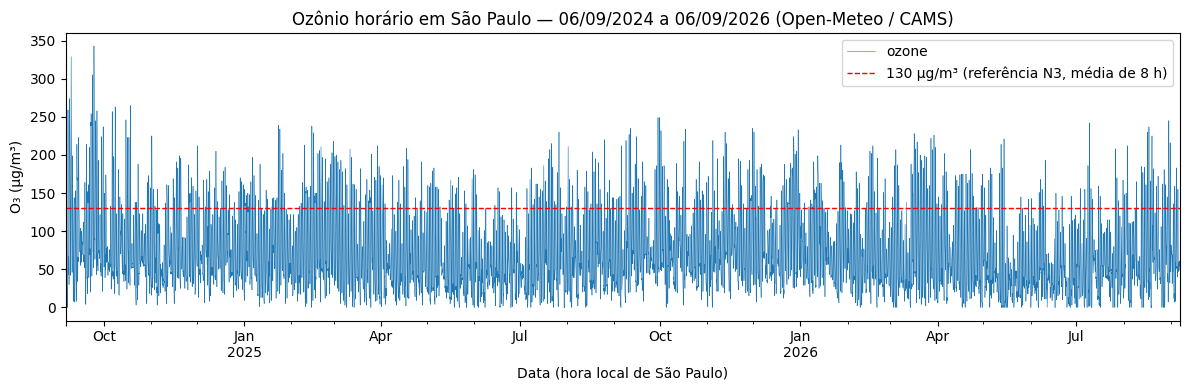

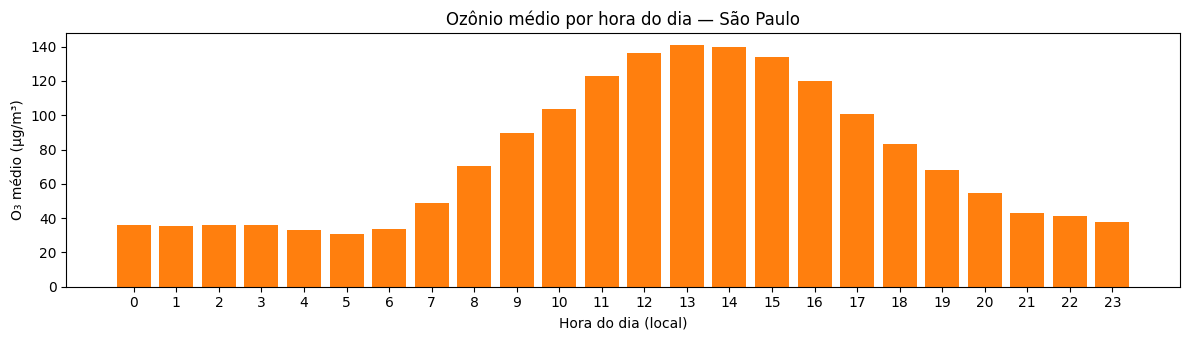

In [16]:
coluna_tempo = "timestamp"
coluna_numerica = "ozone"

ax = df.plot(x=coluna_tempo, y=coluna_numerica, figsize=(12, 4), lw=0.4, legend=False,
             title="Ozônio horário em São Paulo — 06/09/2024 a 06/09/2026 (Open-Meteo / CAMS)")
ax.axhline(130, color="red", ls="--", lw=1, label="130 µg/m³ (referência N3, média de 8 h)")
ax.legend(loc="upper right")
plt.xlabel("Data (hora local de São Paulo)")
plt.ylabel("O₃ (µg/m³)")
plt.tight_layout()
plt.show()

perfil = df.groupby(df[coluna_tempo].dt.hour)[coluna_numerica].mean()
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(perfil.index, perfil.values, color="tab:orange")
ax.set_xticks(range(24))
ax.set_title("Ozônio médio por hora do dia — São Paulo")
plt.xlabel("Hora do dia (local)")
plt.ylabel("O₃ médio (µg/m³)")
plt.tight_layout()
plt.show()

# Parte 5 — Variável-alvo e features

## 22. Alvo sem vazamento

Decisões:

- **Variável que rotula o evento:** as seis concentrações, cada uma na **média móvel da CETESB terminando na hora** (24 h para MP10, MP2,5 e SO₂; 8 h para O₃ e CO; 1 h para NO₂). A média só usa a própria hora e as anteriores.
- **Limiar:** entrada da faixa N3 (tabela da seção 1). Não é escolhido olhando os dados: vem da norma usada pela CETESB, o que evita um limiar "arbitrário". CO é convertido de µg/m³ para ppm por `ppm = µg/m³ × 24,45 / (28,01 × 1000) ≈ µg/m³ × 0,000873` (25 °C, 1 atm).
- **Mesma linha ou futuro?** Futuro: a linha `t` recebe o estado do ar em `t + 24 h` → `.shift(-24)`.
- **Linhas sem alvo:** as **24 últimas** (06/09/2026 00h–23h), porque o futuro delas está fora do período coletado → `dropna`.
- **Colunas excluídas das features:** os indicadores por poluente (`*_ruim`), o `estado_t` deslocado (`estado_futuro`) e o próprio alvo.

> ⚠️ **Correção para o repositório:** o `config/params.yaml` usa SO₂ > **50** µg/m³. A faixa N3 da CETESB para SO₂ (média de 24 h) começa em **40** µg/m³. Neste período a média de 24 h de SO₂ nunca passa de ~25 µg/m³, então os rótulos não mudam — mas o valor documentado deve ser corrigido para 40.

In [17]:
limites = {   # entrada da faixa N3 — RUIM (CETESB)
    "pm10": (24, 100), "pm2_5": (24, 50), "sulphur_dioxide": (24, 40),
    "ozone": (8, 130), "carbon_monoxide": (8, 11), "nitrogen_dioxide": (1, 240),
}
FATOR_CO_PPM = 24.45 / (28.01 * 1000)

assert df["timestamp"].diff().dropna().eq(pd.Timedelta(hours=1)).all(), \
    "shift(-24) só equivale a +24 h se a série for horária e sem lacunas"

flags = pd.DataFrame(index=df.index)
for col, (janela, limite) in limites.items():
    serie = df[col] * FATOR_CO_PPM if col == "carbon_monoxide" else df[col]
    media = serie.rolling(janela, min_periods=janela).mean()      # só t e passado
    flags[f"{col}_ruim"] = (media > limite).where(media.notna())    # NaN se a janela está incompleta

estado_t = flags.any(axis=1).where(flags.notna().all(axis=1))       # classe do ar AGORA (1 = N3+)

coluna_usada_para_rotular = "estado_t (≥ 1 poluente na faixa N3 em t)"
horizonte_em_linhas = config["horizonte_h"]
nome_alvo = "qualidade_inadequada_24h"

df["estado_t"] = estado_t                                       # conhecido em t → pode virar feature (persistência)
df["estado_futuro"] = estado_t.shift(-horizonte_em_linhas)       # NÃO é feature
df[nome_alvo] = df["estado_futuro"]
df = df.dropna(subset=[nome_alvo]).copy()
df[nome_alvo] = df[nome_alvo].astype(int)

print("Linhas com alvo:", len(df), "(", len(df_b) - len(df), "removidas sem futuro conhecido )")
print("\nPoluente responsável pela classe 1 (contagem de horas, pode haver mais de um):")
display(flags.shift(-horizonte_em_linhas).loc[df.index].sum().astype(int).sort_values(ascending=False).to_frame("horas"))

Linhas com alvo: 17520 ( 24 removidas sem futuro conhecido )

Poluente responsável pela classe 1 (contagem de horas, pode haver mais de um):


,horas
ozone_ruim,2097
pm2_5_ruim,229
pm10_ruim,61
sulphur_dioxide_ruim,0
carbon_monoxide_ruim,0
nitrogen_dioxide_ruim,0


Distribuição do alvo — período inteiro


,contagem,%
qualidade_inadequada_24h,,
0,15261,87.11
1,2259,12.89


Treino (antes de 14/04/2026): 14040 linhas, 1960 positivas (13.96%)
Teste  (a partir de 14/04/2026): 3480 linhas, 299 positivas (8.59%)


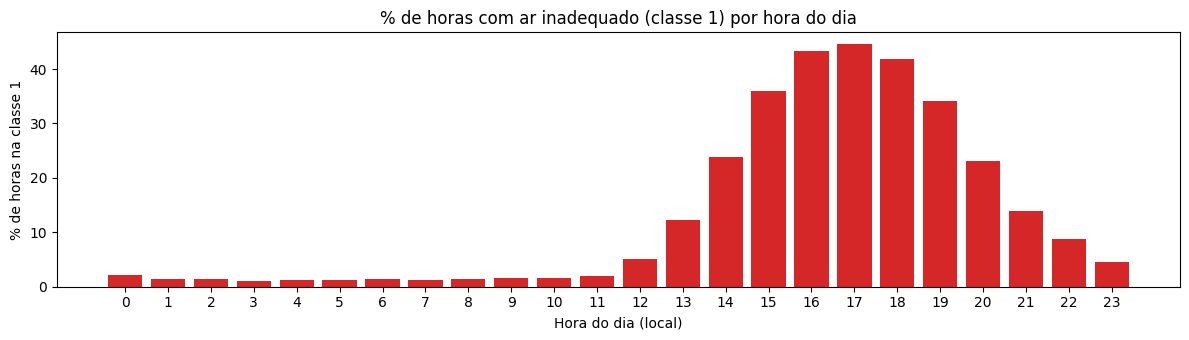

In [18]:
print("Distribuição do alvo — período inteiro")
display(pd.concat([df[nome_alvo].value_counts(),
                   df[nome_alvo].value_counts(normalize=True).mul(100).round(2)],
                  axis=1, keys=["contagem", "%"]))

corte = pd.Timestamp(config["corte_split"])
treino = df[df["timestamp"] < corte]
teste = df[df["timestamp"] >= corte]
print(f"Treino (antes de {corte:%d/%m/%Y}): {len(treino)} linhas, "
      f"{treino[nome_alvo].sum()} positivas ({treino[nome_alvo].mean()*100:.2f}%)")
print(f"Teste  (a partir de {corte:%d/%m/%Y}): {len(teste)} linhas, "
      f"{teste[nome_alvo].sum()} positivas ({teste[nome_alvo].mean()*100:.2f}%)")

taxa_hora = df.groupby(df["timestamp"].dt.hour)[nome_alvo].mean().mul(100)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(taxa_hora.index, taxa_hora.values, color="tab:red")
ax.set_xticks(range(24))
ax.set_title("% de horas com ar inadequado (classe 1) por hora do dia")
plt.xlabel("Hora do dia (local)")
plt.ylabel("% de horas na classe 1")
plt.tight_layout()
plt.show()

**Leitura:** a classe 1 é minoritária (≈ 13 % das horas) → acurácia não serve como métrica, e o `DummyClassifier` terá acurácia alta com recall zero. A taxa é menor no teste (abril–setembro, outono/inverno, menos sol) do que no treino, que inclui dois verões — por isso os resultados do teste devem ser lidos em **contagem** (FN e FP), não só em percentual. A quase totalidade dos positivos vem do **ozônio**, e eles se concentram entre 13 h e 20 h — o treino de manhã cedo quase nunca cai na classe 1.

## 23. Features

Cada feature usa somente valores até `t`. As médias móveis são calculadas **depois de `shift(1)`**, então resumem as 24 h anteriores a `t`.

| Feature | Justificativa |
|---|---|
| 6 poluentes e 3 variáveis meteorológicas em `t` | último valor conhecido no momento da previsão |
| `<variável>_lag_1h` | tendência de curto prazo (subindo ou descendo) |
| `<variável>_lag_24h` | mesmo horário de ontem — o alvo é no mesmo horário de amanhã, então o ciclo diário pesa muito |
| `<variável>_media_24h` | nível de fundo do último dia (acúmulo ou dispersão) |
| `hora` | o ozônio tem ciclo diário forte (gráfico acima); a hora de `t` é a hora do alvo |
| `dia_semana` | tráfego muda no fim de semana (NO₂/CO) |
| `mes` | sazonalidade: mais radiação e O₃ na primavera/verão, mais queimadas e inversão térmica no inverno |
| `estado_t` | se o ar já está ruim agora (base do baseline de persistência) |

**Excluídas:** `timestamp` (identificador; o calendário já está em `hora`/`dia_semana`/`mes`), `estado_futuro` e as `*_ruim` (formam o alvo), e o próprio alvo.

In [19]:
base = df_b[["timestamp"] + poluentes + meteo].copy()   # parte de df_b: série completa, sem buracos
base["estado_t"] = estado_t

for col in poluentes + meteo:
    base[f"{col}_lag_1h"] = base[col].shift(1)
    base[f"{col}_lag_24h"] = base[col].shift(24)
    base[f"{col}_media_24h"] = base[col].shift(1).rolling(24, min_periods=24).mean()
base["hora"] = base["timestamp"].dt.hour
base["dia_semana"] = base["timestamp"].dt.dayofweek
base["mes"] = base["timestamp"].dt.month

features_modelo = (
    poluentes + meteo + ["hora", "dia_semana", "mes"]
    + [f"{c}_{s}" for c in poluentes + meteo for s in ("lag_1h", "lag_24h", "media_24h")]
)
alvo = nome_alvo

proibidas = {"timestamp", "estado_futuro", alvo, *flags.columns}
assert not proibidas & set(features_modelo), "Feature proibida na lista!"

matriz = base.merge(df[["timestamp", alvo]], on="timestamp", how="inner", validate="one_to_one")
matriz = matriz.dropna(subset=features_modelo)     # primeiras 24 h não têm histórico de lag/média
print("Features:", len(features_modelo), "+ estado_t (só para o baseline de persistência)")
print("Linhas com todas as features e alvo:", len(matriz))
display(matriz[["timestamp"] + features_modelo[:6] + [alvo]].head())

Features: 39 + estado_t (só para o baseline de persistência)
Linhas com todas as features e alvo: 17496


,timestamp,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,qualidade_inadequada_24h
24,2024-09-07 00:00:00,28.4,19.7,496.0,42.4,12.5,16.0,1
25,2024-09-07 01:00:00,30.5,21.2,495.0,41.5,12.7,13.0,1
26,2024-09-07 02:00:00,32.5,22.6,490.0,40.0,12.8,10.0,1
27,2024-09-07 03:00:00,34.8,24.3,486.0,39.1,13.3,8.0,1
28,2024-09-07 04:00:00,38.8,27.1,474.0,39.2,14.5,1.0,1


### Teste automático de vazamento

Se uma feature usasse informação futura, recalculá-la **apagando tudo depois de `t`** daria outro valor. O teste abaixo recalcula as features com o DataFrame cortado em vários instantes e confere se o valor em `t` é idêntico ao calculado com a série inteira.

In [20]:
def montar_features(serie):
    out = serie[["timestamp"] + poluentes + meteo].copy()
    for col in poluentes + meteo:
        out[f"{col}_lag_1h"] = out[col].shift(1)
        out[f"{col}_lag_24h"] = out[col].shift(24)
        out[f"{col}_media_24h"] = out[col].shift(1).rolling(24, min_periods=24).mean()
    out["hora"] = out["timestamp"].dt.hour
    out["dia_semana"] = out["timestamp"].dt.dayofweek
    out["mes"] = out["timestamp"].dt.month
    return out[features_modelo]

completo = montar_features(df_b)
for i in [100, 5000, 12000, len(df_b) - 30]:
    cortado = montar_features(df_b.iloc[: i + 1])          # o futuro de t simplesmente não existe aqui
    assert completo.iloc[i].equals(cortado.iloc[i]), f"Vazamento detectado em t = {df_b.timestamp[i]}"
print("OK: nenhuma feature muda quando o futuro é removido → sem vazamento temporal.")

OK: nenhuma feature muda quando o futuro é removido → sem vazamento temporal.


## Limitações dos dados

1. **Dado modelado, não medido.** Os poluentes vêm do CAMS Global (≈ 45 km, passo nativo de 3 h). Não são as estações da CETESB; picos locais (corredor de ônibus, marginal) ficam suavizados. O modelo aprende a prever **o CAMS**, e é isso que o atleta verá.
2. **Um único ponto para a cidade inteira.** Quem corre na USP e quem pedala na Paulista recebem a mesma previsão.
3. **Grades diferentes.** O ponto devolvido pela API de ar (≈ −23,50 / −46,60) é diferente do ponto da API de clima (≈ −23,59 / −46,66); a integração é só temporal.
4. **Clima é reanálise** e os dias mais recentes chegam com alguns dias de atraso — na operação real seria preciso usar a **previsão** do tempo, não o arquivo histórico.
5. **Período curto** (2 anos): cada estação aparece só duas vezes; o teste (abr–set/2026) tem menos positivos que o treino.
6. **Classe 1 dominada pelo ozônio**, ligado a sol e calor. Variáveis como radiação solar (`shortwave_radiation`) e nebulosidade (`cloud_cover`) não foram coletadas e são as candidatas naturais para a Sprint 4.
7. **N3 é um corte de população geral.** Atletas com asma podem precisar de alerta já na faixa N2 (Moderada) — possível nível "Atenção" no produto final.

## Checklist final

- [x] O problema está delimitado (seção 1).
- [x] Os links das documentações foram registrados (seção 2).
- [x] Cada parâmetro da API foi explicado (seção 5).
- [x] Cada feature possui justificativa (seções 7 e 23).
- [x] As unidades foram registradas (seções 2, 6 e 7).
- [x] A resposta bruta foi inspecionada antes da transformação e salva em JSON (seções 6, 8 e 10).
- [x] As datas foram convertidas corretamente (`pd.to_datetime` com formato explícito; passo de 1 h conferido).
- [x] A integração possui chave e cardinalidade justificadas (`inner` + `one_to_one`, seção 11).
- [x] Valores ausentes e duplicados foram verificados (seção 19).
- [x] A classe positiva foi definida (seções 1 e 22).
- [x] Não há informação futura nas features (seção 23 + teste automático).
- [x] As limitações dos dados foram descritas.
- [ ] O notebook executa em ordem depois de preenchido → **executar tudo no Colab e salvar com as saídas.**

In [21]:
resumo = {
    "executado_em_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "n_ar": len(df_ar), "n_clima": len(df_clima), "n_merge": len(df_b),
    "n_com_alvo": len(df), "n_matriz_features": len(matriz),
    "positivos_%": round(df[nome_alvo].mean() * 100, 2),
    "arquivos_brutos": sorted(p.name for p in Path(config["pasta_bruto"]).iterdir()),
}
resumo

{'executado_em_utc': '2026-10-19T05:24:09+00:00',
 'n_ar': 17544,
 'n_clima': 17544,
 'n_merge': 17544,
 'n_com_alvo': 17520,
 'n_matriz_features': 17496,
 'positivos_%': np.float64(12.89),
 'arquivos_brutos': ['air_quality_20240906_20260906.json',
  'integrado.csv',
  'weather_20240906_20260906.json']}